# Notebook 04 - Simulated electrical layer (energy baseline)

**Goal.** The Azure telemetry has no electrical coupling (Notebook 02: largest sensor correlation about 0.003, machines independent). To demonstrate a trust layer that separates a *grid event* from a *sensor fault* we need physically linked quantities. This notebook builds that layer **without any anomaly yet** (anomalies are injected in Notebook 05).

**Core principle: true vs measured.** Every electrical quantity exists twice:
- `*_true`: the physical state of the simulated plant;
- `*_meas`: what the sensor reports (true value + measurement noise).

Grid events (Notebook 05) will change the **true** values and propagate through related signals. Sensor faults will corrupt only the **measured** values.

**Inputs:** `PdM_telemetry.csv` (or the saved parquet) and `PdM_machines.csv`.
**Outputs:** `data/simulated/energy_baseline.parquet`, `data/simulated/feeder_baseline.parquet`, `logs/sim_params.json`, figures `docs/figures/04_*`.

**Units (fixed for the whole project):** V in volts (line-to-line), I in amperes, P in kW, frequency in Hz, power factor dimensionless.
**Relation used:** `P[kW] x 1000 = sqrt(3) x V x I x PF` (balanced three-phase).

> All numbers below are **modelling assumptions**, not measurements. They are gathered in one parameter dictionary (Step 2) and saved to `logs/sim_params.json`.

## Step 1 - Imports, configuration and data loading

In [1]:
# ------------------------------------------------------------------
# Step 1: Imports, shared config (paths + seed) and data loading.
# We reuse src/config.py from Notebook 00 and the helper module
# simulation/electrical.py (formulas shared with Notebook 05).
# ------------------------------------------------------------------
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
sys.path.append(str(ROOT))
from config import RAW, PROCESSED, SIMULATED, LOGS, SEED, N_MACHINES
from simulation import electrical as el

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SIMULATED.mkdir(parents=True, exist_ok=True)
LOGS.mkdir(parents=True, exist_ok=True)

def savefig(name):
    # Save the current figure into docs/figures/ for the report.
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
# ------------------------------------------------------------------
# Step 1b: Load telemetry (fast path first, CSV fallback) and merge the
# machine metadata. Sorting by (machineID, datetime) is essential: the
# whole simulation works on arrays of shape (machines, hours) obtained
# by reshaping this sorted table.
# ------------------------------------------------------------------
if (PROCESSED / "telemetry.parquet").exists():
    tel = pd.read_parquet(PROCESSED / "telemetry.parquet")
elif (PROCESSED / "telemetry.pkl").exists():
    tel = pd.read_pickle(PROCESSED / "telemetry.pkl")
else:
    tel = pd.read_csv(RAW / "PdM_telemetry.csv", parse_dates=["datetime"])

mach = pd.read_csv(RAW / "PdM_machines.csv")
tel = (tel.merge(mach, on="machineID", how="left")
          .sort_values(["machineID", "datetime"])
          .reset_index(drop=True))

# Structural checks: complete (machine x hour) grid, same timestamps for all machines.
machine_ids = np.sort(tel["machineID"].unique())
M = len(machine_ids)
counts = tel.groupby("machineID").size().unique()
assert len(counts) == 1, "machines do not all have the same number of hourly rows"
T = int(counts[0])
times = tel["datetime"].values.reshape(M, T)
assert (times == times[0]).all(), "timestamps differ between machines"
dt = pd.DatetimeIndex(times[0])

print(f"Machines M = {M} (config N_MACHINES = {N_MACHINES}) | hours T = {T}")
print("Period:", dt.min(), "->", dt.max())
print("Models:", sorted(tel["model"].unique()), "| age range:", tel["age"].min(), "-", tel["age"].max())
assert M == N_MACHINES

Machines M = 100 (config N_MACHINES = 100) | hours T = 8761
Period: 2015-01-01 06:00:00 -> 2016-01-01 06:00:00
Models: ['model1', 'model2', 'model3', 'model4'] | age range: 0 - 20


## Step 2 - Assumptions and parameters

Everything the simulation assumes is declared here. **Decisions to confirm or change** (they are the open choices of the Phase 1 report):

| Decision | Default used here | Reason |
|---|---|---|
| Voltage scale | Nominal **400 V** line-to-line (Tunisian low-voltage standard), 50 Hz | The raw `volt` (about 170) is not a real line voltage. It is kept as `volt_raw` and used as the *realisation of the sensor noise*. |
| Grouping | 5 production lines x 20 machines (`line` 1 to 5) | One Noosphere node per line |
| Load model | Load factor driven by a daily/weekly/seasonal profile + real `rotate` and `pressure` | Gives the real mechanical columns a physical role |
| Rated power | By machine model (15 / 22 / 30 / 37 kW) | Placeholder values; replace if you have better ones |
| Age effect | +0.2 % electrical power per year of age | Ties in with the EDA finding that older machines behave differently |
| Power factor | Rises with load: `0.55 + 0.33 x load factor` | Typical induction-motor behaviour |
| Daily / seasonal profile | **Yes** (day peak 14:00, weekends -10 %, summer +5 %) | Raw data has none (Notebook 02) |
| Frequency | 50 Hz + AR(1) noise + small load dependence, common to the whole feeder | Frequency is a system-wide quantity |
| Feeder | Sum of machine powers + 2 % losses; voltage sags slightly with total load | Gives a feeder meter for physics and peer checks |

In [3]:
# ------------------------------------------------------------------
# Step 2: All simulation parameters in ONE place.
# Changing a value here changes the whole dataset; the dictionary is
# saved to logs/sim_params.json so Notebook 05 reuses the same plant.
# ------------------------------------------------------------------
PARAMS = dict(
    seed=SEED,
    v_nom=400.0,                       # V, nominal line-to-line voltage
    f_nom=50.0,                        # Hz
    n_lines=5, machines_per_line=20,   # 5 x 20 = 100 machines
    rated_kw={"model1": 15.0, "model2": 22.0, "model3": 30.0, "model4": 37.0},
    base_load_range=(0.50, 0.70),      # per-machine base load factor ~ U(a, b)
    load_weights={"rotate": 0.06, "pressure": 0.03},   # weight of the real z-scores
    lf_clip=(0.15, 1.05),
    age_loss_per_year=0.002,
    pf_intercept=0.55, pf_slope=0.33, pf_clip=(0.50, 0.92),
    profile=dict(daily_amp=0.15, peak_hour=14, weekend_factor=0.90,
                 seasonal_amp=0.05, seasonal_peak_doy=200),
    feeder=dict(sag_coef=0.03,             # feeder sag per unit of total load ratio
                v_slow_phi=0.995, v_slow_sigma=0.003,   # slow supply variation (fraction)
                line_drop_range=(0.002, 0.008),         # cable drop at full load (fraction)
                loss_fraction=0.02),
    frequency=dict(phi=0.90, sigma=0.02, load_coef=-0.04),
    noise=dict(volt_pct=0.005,       # real volt z-score x 0.5 %
               current_pct=0.010, power_pct=0.010, pf_pct=0.010,
               freq_hz=0.005, feeder_power_pct=0.003),
)
assert PARAMS["n_lines"] * PARAMS["machines_per_line"] == M
rng = np.random.default_rng(PARAMS["seed"])   # single RNG, fixed draw order (reproducible)

## Step 3 - Reshape to (machines x hours) and assign lines

The sorted table is reshaped so that row `i` of every array is machine `machine_ids[i]` and column `t` is hour `t`. This makes the simulation fully vectorised and keeps true and measured layers aligned.

In [4]:
# ------------------------------------------------------------------
# Step 3: Arrays of shape (M, T) + machine attributes + line index.
# z-scores are computed globally so the real telemetry keeps its shape
# but is expressed in dimensionless units.
# ------------------------------------------------------------------
def to_2d(col):
    return tel[col].values.reshape(M, T)

def zscore(a):
    return (a - a.mean()) / a.std()

z_rot  = zscore(to_2d("rotate"))
z_pre  = zscore(to_2d("pressure"))
z_volt = zscore(to_2d("volt"))      # real voltage noise realisation

attrs = tel.groupby("machineID")[["model", "age"]].first().loc[machine_ids]
age   = attrs["age"].values.astype(float)
rated = attrs["model"].map(PARAMS["rated_kw"]).values.astype(float)
assert not np.isnan(rated).any(), "a machine model has no rated power in PARAMS"

line_of_machine = np.arange(M) // PARAMS["machines_per_line"] + 1      # 1..5
print(pd.Series(line_of_machine).value_counts().sort_index().to_dict(), "machines per line")
print(attrs["model"].value_counts().sort_index().to_dict())

{1: 20, 2: 20, 3: 20, 4: 20, 5: 20} machines per line
{'model1': 16, 'model2': 17, 'model3': 35, 'model4': 32}


## Step 4 - Load profile (daily, weekly, seasonal)

The raw data has no daily or seasonal cycle (Notebook 02). We add one explicitly so the plant behaves like a factory: higher load in the afternoon, lower at night and on weekends, slightly higher in summer. The profile is normalised to mean 1, so it changes *when* energy is used, not the average load.

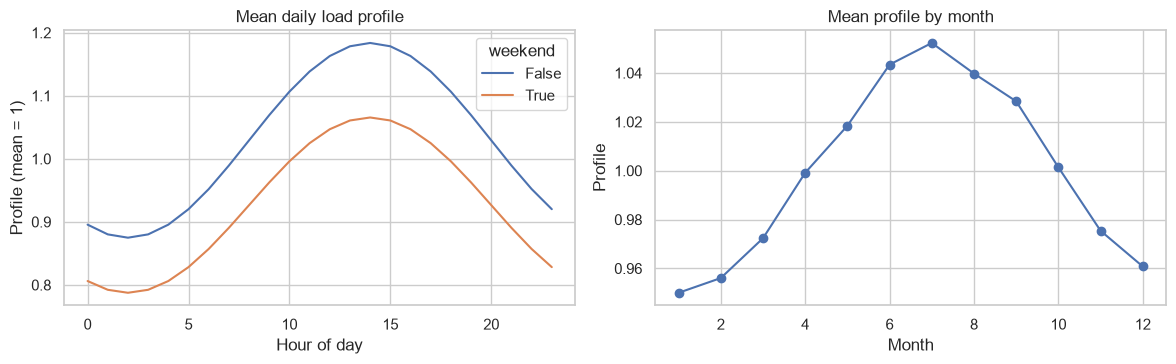

Profile range: 0.75 - 1.24 | mean = 1.000


In [5]:
# ------------------------------------------------------------------
# Step 4: Build the profile (T,) and plot its daily and monthly shape.
# ------------------------------------------------------------------
prof = el.load_profile(dt, **PARAMS["profile"])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
dfp = pd.DataFrame({"prof": prof, "hour": dt.hour, "weekend": dt.dayofweek >= 5, "month": dt.month})
sns.lineplot(data=dfp, x="hour", y="prof", hue="weekend", estimator="mean", errorbar=None, ax=ax[0])
ax[0].set(title="Mean daily load profile", xlabel="Hour of day", ylabel="Profile (mean = 1)")
dfp.groupby("month")["prof"].mean().plot(marker="o", ax=ax[1])
ax[1].set(title="Mean profile by month", xlabel="Month", ylabel="Profile")
plt.tight_layout(); savefig("04_load_profile"); plt.show()
print(f"Profile range: {prof.min():.2f} - {prof.max():.2f} | mean = {prof.mean():.3f}")

## Step 5 - True physical layer

Order of computation (no circular dependency):
1. **Load factor** `lf` of each machine = base load x profile x (1 + weights x real `rotate` / `pressure` z-scores).
2. **Active power** `P_true = rated x lf x (1 + age effect)`.
3. **Feeder**: total load ratio -> feeder voltage (small sag + slow AR(1) supply variation); frequency from an AR(1) plus a small load term.
4. **Machine voltage** `V_true` = feeder voltage minus a cable drop proportional to the machine's load factor.
5. **Power factor** from the load factor, then **current** from `I = P / (sqrt(3) V PF)`.

Because the current is *derived* from P, V and PF, the true quantities satisfy the physical relation exactly. Grid events in Notebook 05 will modify `V_true` (and frequency) and recompute `I_true` with the same function.

In [6]:
# ------------------------------------------------------------------
# Step 5: True electrical quantities. Draw order of the RNG is fixed:
# (1) base load, (2) cable drop, (3) slow voltage, (4) frequency.
# ------------------------------------------------------------------
fd, fq = PARAMS["feeder"], PARAMS["frequency"]
w = PARAMS["load_weights"]

base_lf = rng.uniform(*PARAMS["base_load_range"], size=M)
drop    = rng.uniform(*fd["line_drop_range"], size=M)

# 1-2. Load factor and active power (kW)
lf = base_lf[:, None] * prof[None, :] * (1 + w["rotate"] * z_rot + w["pressure"] * z_pre)
lf = np.clip(lf, *PARAMS["lf_clip"])
p_true = rated[:, None] * lf * (1 + PARAMS["age_loss_per_year"] * age)[:, None]

# 3. Feeder: total load ratio -> feeder voltage and frequency
p_sum  = p_true.sum(axis=0)                                            # (T,) kW
p_ref  = (rated * (1 + PARAMS["age_loss_per_year"] * age)).sum()       # all machines at rating
load_ratio = p_sum / p_ref
v_slow   = el.ar1(T, fd["v_slow_phi"], fd["v_slow_sigma"], rng)
v_feeder = PARAMS["v_nom"] * (1 - fd["sag_coef"] * load_ratio + v_slow)
f_true   = (PARAMS["f_nom"] + el.ar1(T, fq["phi"], fq["sigma"], rng)
            + fq["load_coef"] * (load_ratio - load_ratio.mean()))

# 4-5. Machine voltage, power factor, current
v_true  = v_feeder[None, :] * (1 - drop[:, None] * lf)
pf_true = el.power_factor(lf, PARAMS["pf_intercept"], PARAMS["pf_slope"], PARAMS["pf_clip"])
i_true  = el.current_from_power(p_true, v_true, pf_true)

print(f"P_true  kW : mean {p_true.mean():6.2f} | range {p_true.min():6.2f} - {p_true.max():6.2f}")
print(f"V_true  V  : mean {v_true.mean():6.1f} | range {v_true.min():6.1f} - {v_true.max():6.1f}")
print(f"I_true  A  : mean {i_true.mean():6.1f} | range {i_true.min():6.1f} - {i_true.max():6.1f}")
print(f"PF_true    : mean {pf_true.mean():6.3f} | range {pf_true.min():6.3f} - {pf_true.max():6.3f}")
print(f"f_true  Hz : mean {f_true.mean():6.3f} | range {f_true.min():6.3f} - {f_true.max():6.3f}")

P_true  kW : mean  17.34 | range   4.50 -  39.33
V_true  V  : mean  391.5 | range  385.0 -  397.3
I_true  A  : mean   34.1 | range   10.2 -   65.6
PF_true    : mean  0.747 | range  0.646 -  0.895
f_true  Hz : mean 50.001 | range 49.922 - 50.080


## Step 6 - Measured layer (what the sensors report)

`measured = true x (1 + noise)`. The voltage noise uses the **real `volt` z-scores** of the dataset, so the real telemetry is kept as the sensor-noise realisation; the other noises are simulated with the seeded RNG. Frequency noise is additive (Hz). Faults injected in Notebook 05 will be applied on top of these measured values only.

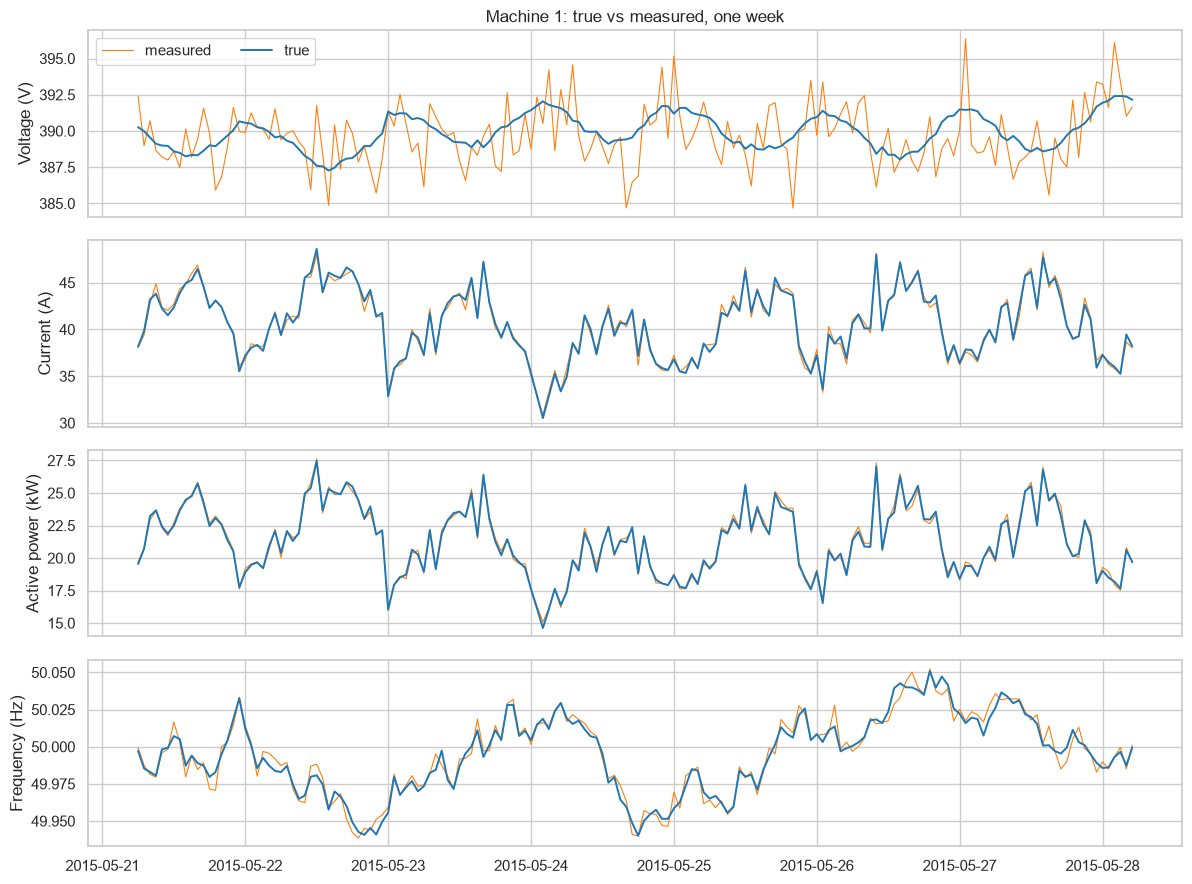

In [7]:
# ------------------------------------------------------------------
# Step 6: Add sensor noise to the true values.
# Noise levels (std, relative) are in PARAMS["noise"].
# ------------------------------------------------------------------
n = PARAMS["noise"]
v_meas  = v_true * (1 + n["volt_pct"] * z_volt)                 # real volt noise
i_meas  = i_true * (1 + n["current_pct"] * rng.standard_normal((M, T)))
p_meas  = p_true * (1 + n["power_pct"]   * rng.standard_normal((M, T)))
pf_meas = np.clip(pf_true * (1 + n["pf_pct"] * rng.standard_normal((M, T))), 0.0, 1.0)
f_meas  = f_true[None, :] + n["freq_hz"] * rng.standard_normal((M, T))

# Visual check: one machine, one week, true vs measured
m_idx, t0, t1 = 0, 24 * 7 * 20, 24 * 7 * 21
fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for a, (tr, me, lab) in zip(ax, [(v_true, v_meas, "Voltage (V)"), (i_true, i_meas, "Current (A)"),
                                 (p_true, p_meas, "Active power (kW)"), (f_true[None, :].repeat(M, 0), f_meas, "Frequency (Hz)")]):
    a.plot(dt[t0:t1], me[m_idx, t0:t1], lw=0.8, color="tab:orange", label="measured")
    a.plot(dt[t0:t1], tr[m_idx, t0:t1], lw=1.4, color="tab:blue", label="true")
    a.set_ylabel(lab)
ax[0].legend(ncol=2); ax[0].set_title(f"Machine {machine_ids[m_idx]}: true vs measured, one week")
plt.tight_layout(); savefig("04_machine_true_vs_measured"); plt.show()

## Step 7 - Physical-consistency check

For the **true** layer the relation `P = sqrt(3) V I PF` must hold to numerical precision. For the **measured** layer the residual is not zero: it is the noise of the four sensors combined. This residual is exactly the evidence the future Physics agent will use: a sensor fault will make it drift away from this normal band.

TRUE     : max |residual| = 4.44e-16  (must be ~ 0)
MEASURED : mean = +0.0002 | std = 0.0180 | 99.9 % band = [-0.057, +0.061]


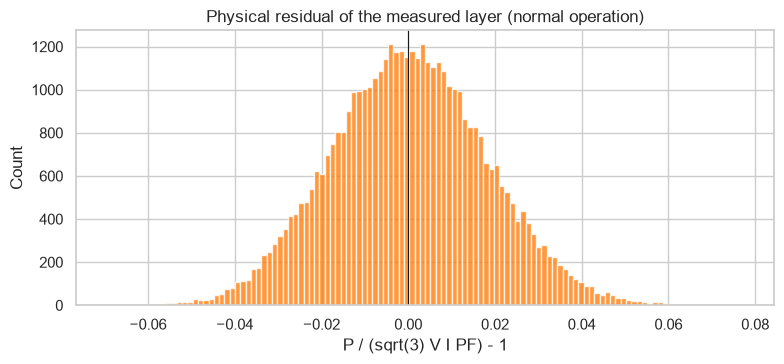

In [8]:
# ------------------------------------------------------------------
# Step 7: Relative residual of P = sqrt(3) V I PF.
# residual = P_reported / P_from(V, I, PF) - 1
# ------------------------------------------------------------------
def rel_residual(p, v, i, pf):
    return p / el.power_from_vi(v, i, pf) - 1.0

res_true = rel_residual(p_true, v_true, i_true, pf_true)
res_meas = rel_residual(p_meas, v_meas, i_meas, pf_meas)

print(f"TRUE     : max |residual| = {np.abs(res_true).max():.2e}  (must be ~ 0)")
print(f"MEASURED : mean = {res_meas.mean():+.4f} | std = {res_meas.std():.4f} | "
      f"99.9 % band = [{np.quantile(res_meas, 0.0005):+.3f}, {np.quantile(res_meas, 0.9995):+.3f}]")
assert np.abs(res_true).max() < 1e-6

plt.figure(figsize=(8, 3.8))
plt.hist(res_meas.ravel()[::20], bins=120, color="tab:orange", alpha=0.8)
plt.axvline(0, color="k", lw=0.8)
plt.title("Physical residual of the measured layer (normal operation)")
plt.xlabel("P / (sqrt(3) V I PF) - 1"); plt.ylabel("Count")
plt.tight_layout(); savefig("04_physics_residual"); plt.show()

## Step 8 - Feeder meter and line totals

The feeder meter measures the total power of the plant, including cable losses. The five **line totals** (20 machines each) are the future Noosphere nodes: a genuine event should show up consistently at feeder and line level, while a single faulty sensor should not.

Feeder power: mean 1769 kW | peak 2220 kW | installed rating 2911 kW | peak/rating = 0.76


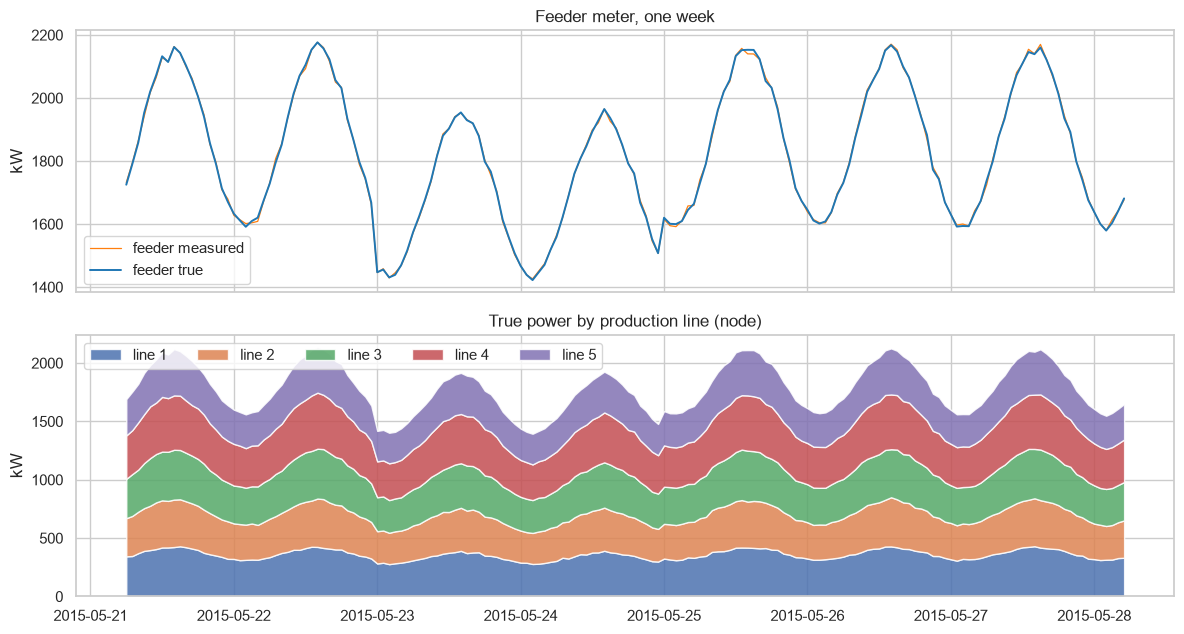

In [9]:
# ------------------------------------------------------------------
# Step 8: Feeder total = sum of machines + losses; line totals by node.
# ------------------------------------------------------------------
p_feeder_true = p_sum * (1 + fd["loss_fraction"])
p_feeder_meas = p_feeder_true * (1 + n["feeder_power_pct"] * rng.standard_normal(T))
p_line_true = p_true.reshape(PARAMS["n_lines"], PARAMS["machines_per_line"], T).sum(axis=1)   # (5, T)

# Consistency: lines add up to the machine total; feeder = total + losses
assert np.allclose(p_line_true.sum(axis=0), p_sum)
print(f"Feeder power: mean {p_feeder_true.mean():.0f} kW | peak {p_feeder_true.max():.0f} kW "
      f"| installed rating {p_ref:.0f} kW | peak/rating = {p_feeder_true.max()/p_ref:.2f}")

w0, w1 = 24 * 7 * 20, 24 * 7 * 21
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].plot(dt[w0:w1], p_feeder_meas[w0:w1], lw=0.9, color="tab:orange", label="feeder measured")
ax[0].plot(dt[w0:w1], p_feeder_true[w0:w1], lw=1.4, color="tab:blue", label="feeder true")
ax[0].set_ylabel("kW"); ax[0].legend(); ax[0].set_title("Feeder meter, one week")
ax[1].stackplot(dt[w0:w1], p_line_true[:, w0:w1], labels=[f"line {k}" for k in range(1, 6)], alpha=0.85)
ax[1].set_ylabel("kW"); ax[1].legend(ncol=5, loc="upper left"); ax[1].set_title("True power by production line (node)")
plt.tight_layout(); savefig("04_feeder_and_lines"); plt.show()

## Step 9 - Coupling and sanity checks

Two things to verify:
1. The simulated electrical quantities are now **linked to each other and to the real mechanical columns** (before: correlations about 0.003).
2. Cross-machine behaviour: in the raw data machines are independent (correlation about 0.0001). With a shared feeder, true voltages move together, which is what makes a genuine grid event distinguishable from a single faulty sensor. Measured voltages are less correlated because each sensor adds its own noise.

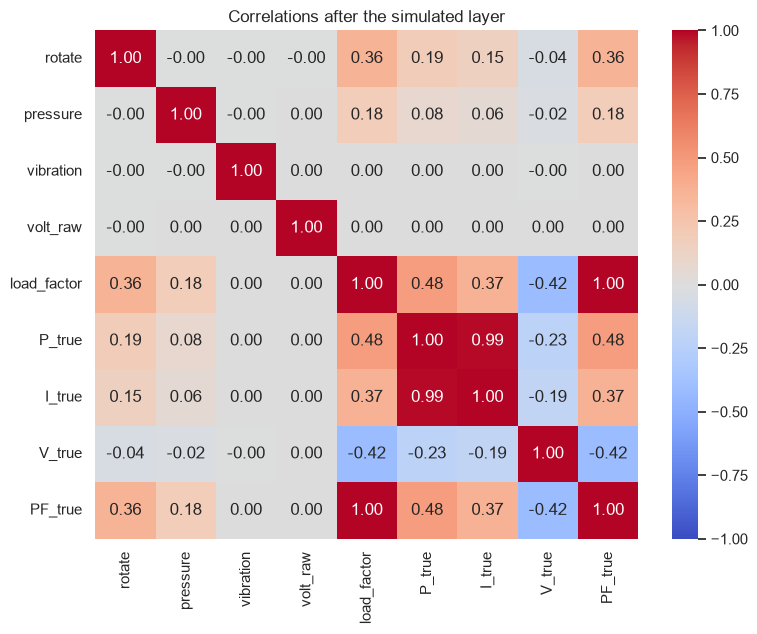

In [10]:
# ------------------------------------------------------------------
# Step 9a: Correlations between the real mechanical columns and the
# simulated electrical quantities (subsampled for speed).
# ------------------------------------------------------------------
idx = rng.choice(M * T, size=200_000, replace=False)
sample = pd.DataFrame({
    "rotate": tel["rotate"].values[idx], "pressure": tel["pressure"].values[idx],
    "vibration": tel["vibration"].values[idx], "volt_raw": tel["volt"].values[idx],
    "load_factor": lf.ravel()[idx], "P_true": p_true.ravel()[idx], "I_true": i_true.ravel()[idx],
    "V_true": v_true.ravel()[idx], "PF_true": pf_true.ravel()[idx],
})
plt.figure(figsize=(8, 6.5))
sns.heatmap(sample.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlations after the simulated layer")
plt.tight_layout(); savefig("04_coupling"); plt.show()

In [11]:
# ------------------------------------------------------------------
# Step 9b: Cross-machine correlation (mean of off-diagonal terms) and
# range checks against expected physical bands.
# ------------------------------------------------------------------
def mean_offdiag_corr(a):
    c = np.corrcoef(a)
    return (c.sum() - np.trace(c)) / (c.size - len(c))

print("Mean cross-machine correlation of voltage:")
print(f"  raw dataset volt : {mean_offdiag_corr(to_2d('volt')):+.4f}")
print(f"  V_true           : {mean_offdiag_corr(v_true):+.4f}")
print(f"  V_meas           : {mean_offdiag_corr(v_meas):+.4f}")

bands = pd.DataFrame([
    ("V_true (V)",  v_true.min(),  v_true.max(),  0.90 * PARAMS["v_nom"], 1.10 * PARAMS["v_nom"]),
    ("f_true (Hz)", f_true.min(),  f_true.max(),  49.8, 50.2),
    ("PF_true",     pf_true.min(), pf_true.max(), PARAMS["pf_clip"][0], PARAMS["pf_clip"][1]),
    ("load factor", lf.min(),      lf.max(),      PARAMS["lf_clip"][0], PARAMS["lf_clip"][1]),
], columns=["quantity", "min", "max", "expected_min", "expected_max"])
bands["ok"] = (bands["min"] >= bands["expected_min"] - 1e-9) & (bands["max"] <= bands["expected_max"] + 1e-9)
display(bands.round(3))

Mean cross-machine correlation of voltage:
  raw dataset volt : +0.0001
  V_true           : +0.9968
  V_meas           : +0.4102


,quantity,min,max,expected_min,expected_max,ok
0,V_true (V),384.967,397.310,360.00,440.00,True
1,f_true (Hz),49.922,50.080,49.80,50.20,True
2,PF_true,0.646,0.895,0.50,0.92,True
3,load factor,0.291,1.045,0.15,1.05,True


## Step 10 - Save the baseline dataset and the parameters

Two tables are saved in `data/simulated/` (git-ignored, regenerated from the seed):
- `energy_baseline`: one row per (machine, hour) with the **raw mechanical columns**, the **true** layer and the **measured** layer.
- `feeder_baseline`: one row per hour with the feeder meter, frequency and the five line totals.

No label column exists yet: `label_class` and the injection log are created in Notebook 05.

In [12]:
# ------------------------------------------------------------------
# Step 10: Assemble the long table (machine-major order, same as the
# sorted telemetry), cast numbers to float32 and save.
# ------------------------------------------------------------------
f32 = lambda a: np.asarray(a, dtype=np.float32).ravel()

sim = pd.DataFrame({
    "datetime": tel["datetime"].values, "machineID": tel["machineID"].values,
    "line": np.repeat(line_of_machine, T).astype(np.int8),
    "model": tel["model"].values, "age": tel["age"].values,
    # real mechanical context
    "volt_raw": f32(tel["volt"]), "rotate": f32(tel["rotate"]),
    "pressure": f32(tel["pressure"]), "vibration": f32(tel["vibration"]),
    # true physical layer
    "load_factor": f32(lf), "v_true": f32(v_true), "i_true": f32(i_true),
    "p_true": f32(p_true), "pf_true": f32(pf_true),
    "f_true": f32(np.broadcast_to(f_true, (M, T))),
    # measured layer
    "v_meas": f32(v_meas), "i_meas": f32(i_meas), "p_meas": f32(p_meas),
    "pf_meas": f32(pf_meas), "f_meas": f32(f_meas),
})

feeder = pd.DataFrame({
    "datetime": dt, "v_feeder_true": f32(v_feeder), "f_true": f32(f_true),
    "p_feeder_true": f32(p_feeder_true), "p_feeder_meas": f32(p_feeder_meas),
    "e_kwh_meas": f32(p_feeder_meas),            # hourly step: kWh = kW x 1 h
    **{f"p_line{k+1}_true": f32(p_line_true[k]) for k in range(PARAMS["n_lines"])},
})

def save_table(df, name):
    # Parquet if pyarrow is available, pickle otherwise (same convention as Notebook 01).
    try:
        df.to_parquet(SIMULATED / f"{name}.parquet", index=False); return "parquet"
    except Exception as e:
        df.to_pickle(SIMULATED / f"{name}.pkl"); return f"pickle ({type(e).__name__})"

print("energy_baseline :", sim.shape, "->", save_table(sim, "energy_baseline"))
print("feeder_baseline :", feeder.shape, "->", save_table(feeder, "feeder_baseline"))

summary = dict(rows=int(len(sim)), machines=int(M), hours=int(T),
               true_residual_max=float(np.abs(res_true).max()),
               measured_residual_std=float(res_meas.std()),
               peak_over_rating=float(p_feeder_true.max() / p_ref))
(LOGS / "sim_params.json").write_text(json.dumps({"params": PARAMS, "summary": summary}, indent=2, default=list),
                                      encoding="utf-8")
display(sim.head(3))
print(json.dumps(summary, indent=2))

energy_baseline : (876100, 20) -> parquet
feeder_baseline : (8761, 11) -> parquet


,datetime,machineID,line,model,age,volt_raw,rotate,pressure,vibration,load_factor,v_true,i_true,p_true,pf_true,f_true,v_meas,i_meas,p_meas,pf_meas,f_meas
0,2015-01-01 06:00:00,1,1,model3,18,176.217850,418.504089,113.077934,45.087685,0.594225,390.210297,36.625103,18.468512,0.746094,50.028297,390.894653,36.900509,18.022760,0.739887,50.030285
1,2015-01-01 07:00:00,1,1,model3,18,162.879227,402.747498,95.460526,43.413971,0.576894,389.910126,35.859138,17.929850,0.740375,50.018047,388.917267,35.043438,17.733595,0.736080,50.019817
2,2015-01-01 08:00:00,1,1,model3,18,170.989899,527.349854,75.237907,34.178848,0.656034,389.357605,39.444881,20.389523,0.766491,50.000267,389.384216,39.461025,20.281723,0.770126,49.996262


{
  "rows": 876100,
  "machines": 100,
  "hours": 8761,
  "true_residual_max": 4.440892098500626e-16,
  "measured_residual_std": 0.018030250687317857,
  "peak_over_rating": 0.7625103991385735
}


## Summary and next step

- The plant now has a **true** physical layer and a **measured** sensor layer, linked by `P = sqrt(3) V I PF`, a shared feeder, a daily/weekly/seasonal load and the real mechanical telemetry.
- The measured-layer physical residual defines the **normal band** the Physics agent will monitor.
- Everything is reproducible from `SEED` and documented in `logs/sim_params.json`.

**Limitations to state in the report:** rated powers, power-factor law, cable drops and noise levels are assumptions; the voltage noise is the real dataset signal but the physical variation is simulated; no real grid data is involved.

**Next: Notebook 05 (scenario generation)** will load `energy_baseline`, inject sensor faults (on `*_meas` only), grid events and outages (on `*_true`, recomputing current with `el.current_from_power`), and equipment degradation, and write the labelled dataset plus `injection_log.csv`.